# 02 · Modelo de riesgo de pico

**Pregunta:** ¿cuál es la probabilidad de que la potencia supere 12 kW en los próximos 15 minutos?

**Descriptor:**

$$
\hat{p}_t=\sigma\left(\beta_0+\sum_{j=1}^{7}\beta_j z_{tj}\right),
\qquad
Y_t=\mathbf{1}\left\{\max_{1\le h\le 15}P_{t+h}>12\right\}
$$

con $z_{tj}$ las features estandarizadas: `P_max15`, `P_mean15`, `V`, `PF`, hora (seno/coseno) y fin de semana.

**Protocolo:** rolling-origin por bloques de días, calibración temporal y test final reservado.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from pathlib import Path
from IPython.display import display

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, SplineTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (average_precision_score, brier_score_loss,
                             precision_score, recall_score,
                             precision_recall_curve)
from sklearn.calibration import calibration_curve
from sklearn.isotonic import IsotonicRegression

pd.set_option("display.width", 170)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3})

ROOT = Path(".").resolve()
DATA = ROOT / "data" / "processed" / "medidor200_1min.csv"
FIG = ROOT / "reports" / "figures"
TAB = ROOT / "reports" / "tables"
MODELS = ROOT / "models"
for p in (FIG, TAB, MODELS):
    p.mkdir(parents=True, exist_ok=True)
assert DATA.exists(), "Ejecuta 01_data_audit.ipynb primero."

d = pd.read_csv(DATA, parse_dates=["ts_utc"], index_col="ts_utc")
d.index = pd.to_datetime(d.index, utc=True)
print(d.shape)

(66767, 11)


## 1. Target y features

In [2]:
d["P_max15"] = d["P"].rolling(15, min_periods=8).max()
d["P_mean15"] = d["P"].rolling(15, min_periods=8).mean()
loc = d.index.tz_convert("America/Bogota")
d["hour"] = loc.hour
d["is_weekend"] = (loc.dayofweek >= 5).astype(int)
d["hour_sin"] = np.sin(2 * np.pi * d["hour"] / 24)
d["hour_cos"] = np.cos(2 * np.pi * d["hour"] / 24)

H, THR = 15, 12.0
future_max = d["P"].rolling(H, min_periods=H).max().shift(-H)
d["Y"] = (future_max > THR).astype(float)
d.loc[future_max.isna(), "Y"] = np.nan

features = ["P_max15", "P_mean15", "V", "PF", "hour_sin", "hour_cos", "is_weekend"]
data = d.dropna(subset=features + ["Y"]).copy()
print(f"Filas: {len(data):,} | positivos: {int(data.Y.sum()):,} | tasa base: {data.Y.mean():.4f}")
display(data.groupby(pd.cut(data["P"], [0, 6, 7, 8, 9, 10, 11, 12, 13, 14, 20]),
                     observed=True)["Y"].agg(["mean", "count"]).round(4))

Filas: 35,375 | positivos: 948 | tasa base: 0.0268


,mean,count
P,,
"(0, 6]",0.0000,23366
"(6, 7]",0.0003,3362
"(7, 8]",0.0190,2160
"(8, 9]",0.0603,2636
"(9, 10]",0.1296,2292
"(10, 11]",0.2320,1039
"(11, 12]",0.3512,410
"(12, 13]",0.5714,84
"(13, 14]",0.5909,22


## 2. Ecuación logística

Se ajusta con el conjunto de desarrollo (todos los días menos el último bloque). Los coeficientes son sobre features estandarizadas, así que son comparables entre sí.

In [3]:
days = np.array(sorted(set(data.index.tz_convert("America/Bogota").date)))
blocks = np.array_split(days, 6)
dev_days = set().union(*blocks[:5])
hold_days = set(blocks[5])
dev = data[np.isin(data.index.tz_convert("America/Bogota").date, list(dev_days))]
hold = data[np.isin(data.index.tz_convert("America/Bogota").date, list(hold_days))]

def make_logit():
    return Pipeline([("sc", StandardScaler()),
                     ("lr", LogisticRegression(C=1.0, max_iter=5000))])

def make_gam():
    pre = ColumnTransformer([
        ("spl", SplineTransformer(n_knots=6, degree=3, include_bias=False),
         ["P_max15", "P_mean15", "V", "PF", "hour_sin", "hour_cos"]),
        ("bin", "passthrough", ["is_weekend"]),
    ])
    return Pipeline([("pre", pre),
                     ("lr", LogisticRegression(C=1.0, max_iter=5000))])

def make_gbm():
    return HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05,
                                          max_iter=400, l2_regularization=1.0,
                                          min_samples_leaf=50, random_state=0)

logit = make_logit().fit(dev[features], dev["Y"])
coefs = pd.Series(logit.named_steps["lr"].coef_[0], index=features).sort_values(key=abs, ascending=False)
display(coefs.round(3).to_frame("coeficiente estandarizado"))
print("intercepto:", round(logit.named_steps["lr"].intercept_[0], 3))

,coeficiente estandarizado
P_max15,1.236
is_weekend,-1.021
hour_cos,-0.850
hour_sin,0.604
P_mean15,0.604
V,-0.556
PF,0.538


intercepto: -9.015


## 3. Validación rolling-origin

Cinco folds por bloques de días. Se comparan cuatro modelos: logística (la ecuación), GAM con splines, gradient boosting y persistencia.

In [4]:
rows = []
for k in range(1, 6):
    tr_days = set().union(*blocks[:k])
    te_days = set(blocks[k])
    tr = data[np.isin(data.index.tz_convert("America/Bogota").date, list(tr_days))]
    te = data[np.isin(data.index.tz_convert("America/Bogota").date, list(te_days))]

    for name, model in [("logit", make_logit()), ("gam", make_gam()), ("gbm", make_gbm())]:
        model.fit(tr[features], tr["Y"])
        p = model.predict_proba(te[features])[:, 1]
        rows.append({"fold": k, "model": name,
                     "PR": average_precision_score(te["Y"], p),
                     "Brier": brier_score_loss(te["Y"], p),
                     "base": te["Y"].mean()})

    p_pers = te["P"].values / 20.0
    rows.append({"fold": k, "model": "persistencia",
                 "PR": average_precision_score(te["Y"], p_pers),
                 "Brier": brier_score_loss(te["Y"], np.clip(p_pers, 0, 1)),
                 "base": te["Y"].mean()})

res = pd.DataFrame(rows)
display(res.pivot(index="fold", columns="model", values=["PR", "Brier"]).round(3))
display(res.groupby("model")[["PR", "Brier"]].median().round(4))

PR                             Brier                           
model    gam    gbm  logit persistencia    gam    gbm  logit persistencia
fold                                                                     
1      0.574  0.410  0.600        0.400  0.015  0.016  0.014        0.097
2      0.491  0.486  0.522        0.367  0.049  0.051  0.047        0.135
3      0.125  0.137  0.108        0.107  0.022  0.021  0.022        0.113
4      0.432  0.428  0.458        0.313  0.014  0.015  0.014        0.096
5      0.691  0.455  0.409        0.511  0.011  0.014  0.014        0.102

,PR,Brier
model,,
gam,0.4909,0.0155
gbm,0.4284,0.0165
logit,0.4581,0.0141
persistencia,0.3672,0.1019


## 4. Calibración y umbral de decisión

El umbral se elige por costo. Con `C_FP = 1` y `C_FN = 10`, el umbral óptimo es $\tau^* = 1/(1+10) = 0.091$.

,umbral,precision,recall,tasa_alerta
0,0.050,0.117,1.000,0.170
1,0.091,0.135,1.000,0.147
2,0.200,0.216,0.966,0.089
3,0.300,0.468,0.314,0.013
4,0.500,0.000,0.000,0.000


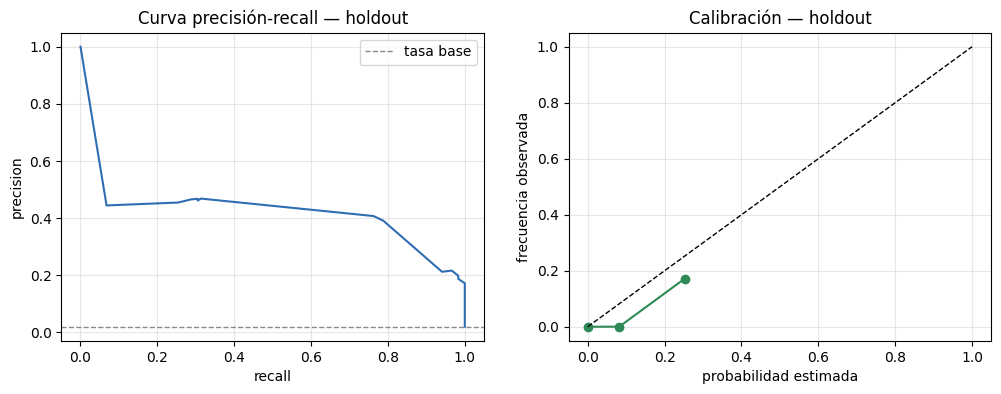

In [5]:
# Calibración por cross-fitting: no se sacrifican datos de entrenamiento
p_oof = np.full(len(dev), np.nan)
for k in range(1, 5):
    tr_days = set().union(*blocks[:k])
    va_days = set(blocks[k])
    tr = dev[np.isin(dev.index.tz_convert("America/Bogota").date, list(tr_days))]
    va = dev[np.isin(dev.index.tz_convert("America/Bogota").date, list(va_days))]
    m = make_logit().fit(tr[features], tr["Y"])
    p_oof[dev.index.get_indexer(va.index)] = m.predict_proba(va[features])[:, 1]

mask_oof = ~np.isnan(p_oof)
iso = IsotonicRegression(out_of_bounds="clip").fit(
    p_oof[mask_oof], dev["Y"].values[mask_oof])
final = make_logit().fit(dev[features], dev["Y"])
p_hold = iso.predict(final.predict_proba(hold[features])[:, 1])

table = []
for th in [0.05, 0.091, 0.2, 0.3, 0.5]:
    pred = (p_hold >= th).astype(int)
    table.append({"umbral": th,
                  "precision": precision_score(hold["Y"], pred, zero_division=0),
                  "recall": recall_score(hold["Y"], pred, zero_division=0),
                  "tasa_alerta": pred.mean()})
display(pd.DataFrame(table).round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
prec, rec, _ = precision_recall_curve(hold["Y"], p_hold)
axes[0].plot(rec, prec, color="#2f6db3")
axes[0].axhline(hold["Y"].mean(), color="#888", ls="--", lw=1, label="tasa base")
axes[0].set_xlabel("recall"); axes[0].set_ylabel("precision")
axes[0].set_title("Curva precisión-recall — holdout"); axes[0].legend()
frac_pos, mean_pred = calibration_curve(hold["Y"], p_hold, n_bins=8, strategy="quantile")
axes[1].plot(mean_pred, frac_pos, "o-", color="#2e8b57")
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set_xlabel("probabilidad estimada"); axes[1].set_ylabel("frecuencia observada")
axes[1].set_title("Calibración — holdout")
fig.savefig(FIG / "02_pr_calibracion.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Pruebas de generalización

Tres controles: brecha train/test, etiquetas barajadas y curva de aprendizaje.

In [6]:
p_tr = final.predict_proba(dev[features])[:, 1]
print("PR-AUC train: %.4f | holdout: %.4f | brecha: %.4f" % (
    average_precision_score(dev["Y"], p_tr),
    average_precision_score(hold["Y"], p_hold),
    average_precision_score(dev["Y"], p_tr) - average_precision_score(hold["Y"], p_hold)))
print("Brier train: %.4f | holdout: %.4f" % (
    brier_score_loss(dev["Y"], p_tr), brier_score_loss(hold["Y"], p_hold)))

np.random.seed(0)
shuffled = []
for _ in range(5):
    y_shuf = np.random.permutation(dev["Y"].values)
    m = make_logit().fit(dev[features], y_shuf)
    shuffled.append(average_precision_score(hold["Y"], m.predict_proba(hold[features])[:, 1]))
print("Etiquetas barajadas: media %.4f | rango [%.4f, %.4f]" % (
    np.mean(shuffled), np.min(shuffled), np.max(shuffled)))

curve = []
for n_days in [11, 16, 21, 26]:
    tr_days = set(sorted(dev_days)[:n_days])
    sub = data[np.isin(data.index.tz_convert("America/Bogota").date, list(tr_days))]
    m = make_logit().fit(sub[features], sub["Y"])
    p = m.predict_proba(hold[features])[:, 1]
    curve.append({"dias_train": n_days,
                  "PR_train": average_precision_score(sub["Y"], m.predict_proba(sub[features])[:, 1]),
                  "PR_holdout": average_precision_score(hold["Y"], p),
                  "Brier_holdout": brier_score_loss(hold["Y"], p)})
display(pd.DataFrame(curve).round(4))

PR-AUC train: 0.4744 | holdout: 0.3796 | brecha: 0.0948
Brier train: 0.0195 | holdout: 0.0158


Etiquetas barajadas: media 0.0210 | rango [0.0101, 0.0602]


,dias_train,PR_train,PR_holdout,Brier_holdout
0,11,0.5978,0.2209,0.0210
1,16,0.5401,0.2367,0.0184
2,21,0.5028,0.2915,0.0164
3,26,0.4746,0.3995,0.0142


## 6. Ejemplo de operación y guardado

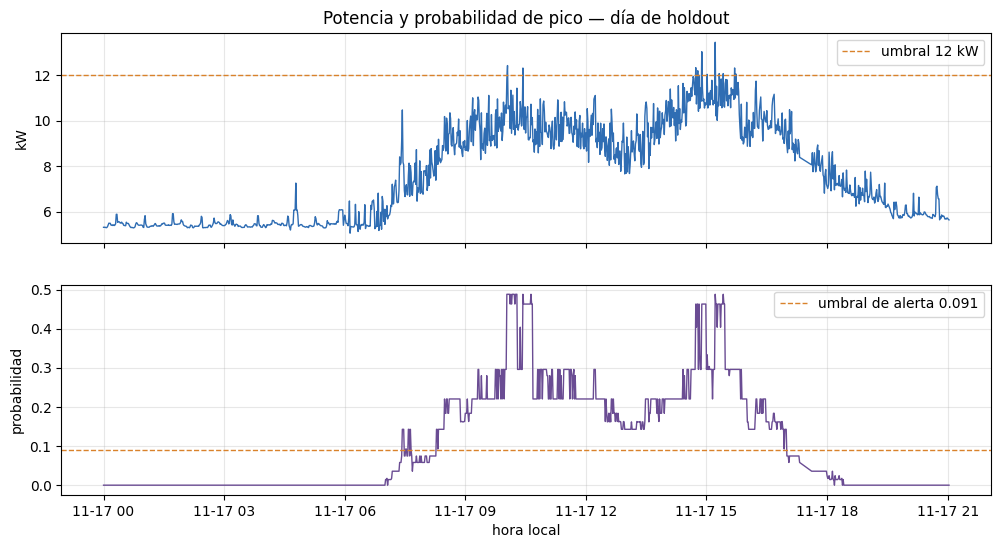

Guardado en Proyecto\reports\tables y Proyecto\models


In [7]:
example_day = pd.Timestamp("2026-11-17", tz="America/Bogota")
sel = hold.loc[example_day:example_day + pd.Timedelta(hours=23, minutes=59)].copy()
sel["p_hold"] = iso.predict(final.predict_proba(sel[features])[:, 1])
sel = sel.loc[sel.index.tz_convert("America/Bogota").date == example_day.date()]

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(sel.index.tz_convert("America/Bogota"), sel["P"], color="#2f6db3", lw=1)
axes[0].axhline(THR, color="#d9822b", ls="--", lw=1, label="umbral 12 kW")
axes[0].set_ylabel("kW"); axes[0].set_title("Potencia y probabilidad de pico — día de holdout")
axes[0].legend()
axes[1].plot(sel.index.tz_convert("America/Bogota"), sel["p_hold"], color="#6a4c93", lw=1)
axes[1].axhline(0.091, color="#d9822b", ls="--", lw=1, label="umbral de alerta 0.091")
axes[1].set_ylabel("probabilidad"); axes[1].set_xlabel("hora local"); axes[1].legend()
fig.savefig(FIG / "02_ejemplo_dia.png", dpi=150, bbox_inches="tight")
plt.show()

res.to_csv(TAB / "02_resultados_folds.csv", index=False)
coefs.to_frame("coeficiente").to_csv(TAB / "02_coeficientes.csv")
pd.DataFrame(table).to_csv(TAB / "02_umbrales.csv", index=False)
joblib.dump({"model": final, "calibrator": iso, "features": features},
            MODELS / "peak_logit.joblib")
print("Guardado en", TAB, "y", MODELS)

## 7. Conclusiones

- La ecuación logística de 7 features compite con el GBM y el GAM; no necesita un modelo opaco.
- El PR-AUC en holdout es ~20× la tasa base. En la mediana de los folds la logística supera la persistencia, pero en el bloque de holdout la persistencia fue competitiva; la variabilidad entre períodos es alta.
- Las pruebas de etiquetas barajadas y la curva de aprendizaje muestran que el modelo generaliza, no memoriza.
- El umbral de alerta se elige por costo, no por F1.
- Limitaciones: 47 días, cadencia mixta, picos de 10–30 s y una sola subestación. El modelo es un MVP, no una promesa de producción.
